Write a program to implement the local binary pattern on gray scale
image.

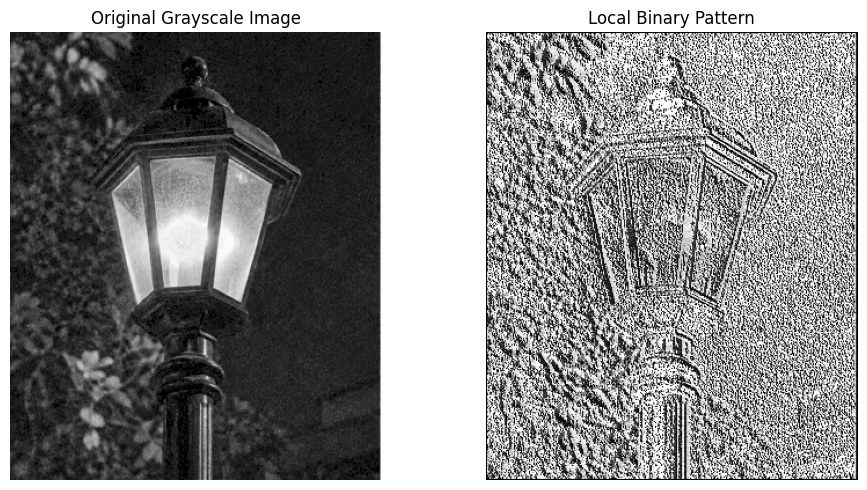

In [1]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Read the input image
img = cv2.imread('/content/denoising.png', cv2.IMREAD_GRAYSCALE)

# Check whether image is loaded
if img is None:
    print("Image not found!")
    exit()

# Step 2: Get image dimensions
height, width = img.shape

# Step 3: Create an output image
lbp = np.zeros((height, width), dtype=np.uint8)

# Step 4: Apply Local Binary Pattern
for i in range(1, height - 1):
    for j in range(1, width - 1):

        center = img[i, j]
        binary = []

        # Get 8 neighboring pixels
        neighbors = [
            img[i-1, j-1],  # Top-left
            img[i-1, j],    # Top
            img[i-1, j+1],  # Top-right
            img[i, j+1],    # Right
            img[i+1, j+1],  # Bottom-right
            img[i+1, j],    # Bottom
            img[i+1, j-1],  # Bottom-left
            img[i, j-1]     # Left
        ]

        # Compare neighbors with center pixel
        for pixel in neighbors:
            if pixel >= center:
                binary.append(1)
            else:
                binary.append(0)

        # Convert binary pattern to decimal
        decimal_value = 0

        for k in range(8):
            decimal_value += binary[k] * (2 ** k)

        lbp[i, j] = decimal_value

# Step 5: Display original and LBP images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Grayscale Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(lbp, cmap='gray')
plt.title('Local Binary Pattern')
plt.axis('off')

plt.tight_layout()
plt.show()


Write a program to denoise the input image corrupted by Gaussian and
Speckle noise

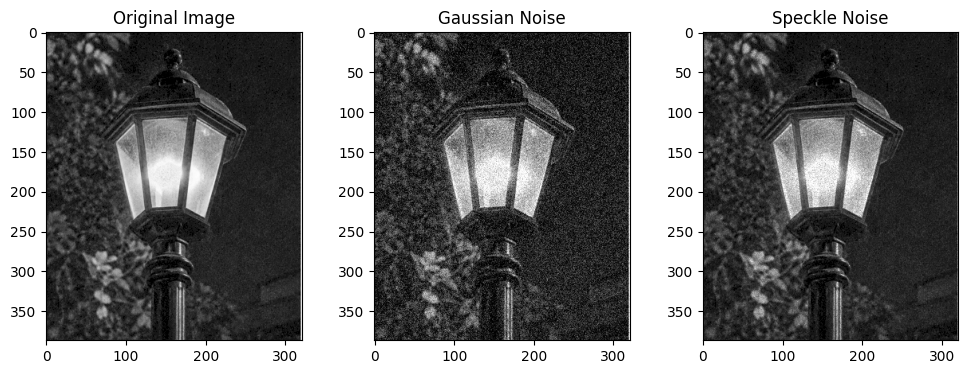

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read input image
img = cv2.imread('/content/denoising.png', cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Image not found!")
    exit()

# Normalize image
img_float = img.astype(np.float32) / 255.0

# Generate Gaussian noise
gaussian_noise = np.random.normal(0, 0.1, img.shape)
gaussian_noisy = np.clip(img_float + gaussian_noise, 0, 1)

# Generate Speckle noise
speckle_noise = np.random.normal(0, 0.1, img.shape)
speckle_noisy = np.clip(
    img_float + img_float * speckle_noise, 0, 1
)

# Convert to uint8
gaussian_noisy = (gaussian_noisy * 255).astype(np.uint8)
speckle_noisy = (speckle_noisy * 255).astype(np.uint8)

# Display images
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')

plt.subplot(1, 3, 2)
plt.imshow(gaussian_noisy, cmap='gray')
plt.title('Gaussian Noise')

plt.subplot(1, 3, 3)
plt.imshow(speckle_noisy, cmap='gray')
plt.title('Speckle Noise')

plt.show()

(a) Wiener Filter

/usr/local/lib/python3.13/dist-packages/scipy/signal/_signaltools.py:1783: RuntimeWarning: divide by zero encountered in divide
  res *= (1 - noise / lVar)


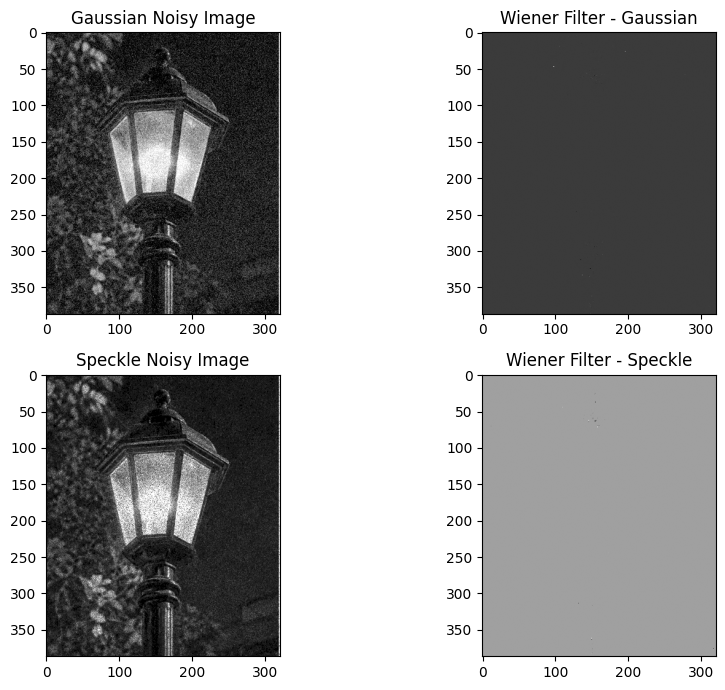

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import wiener

# Read image
img = cv2.imread('/content/denoising.png', 0)

# Generate Gaussian noise
gaussian = np.random.normal(0, 20, img.shape)
gaussian_noisy = np.clip(img.astype(float) + gaussian, 0, 255).astype(np.uint8)

# Generate Speckle noise
speckle = np.random.normal(0, 0.2, img.shape)
speckle_noisy = np.clip(
    img.astype(float) + img.astype(float) * speckle, 0, 255
).astype(np.uint8)

# Apply Wiener filter (3x3)
gaussian_filtered = wiener(gaussian_noisy, (3, 3))
speckle_filtered = wiener(speckle_noisy, (3, 3))

# Display results
plt.figure(figsize=(10, 7))

plt.subplot(2, 2, 1)
plt.imshow(gaussian_noisy, cmap='gray')
plt.title('Gaussian Noisy Image')

plt.subplot(2, 2, 2)
plt.imshow(gaussian_filtered, cmap='gray')
plt.title('Wiener Filter - Gaussian')

plt.subplot(2, 2, 3)
plt.imshow(speckle_noisy, cmap='gray')
plt.title('Speckle Noisy Image')

plt.subplot(2, 2, 4)
plt.imshow(speckle_filtered, cmap='gray')
plt.title('Wiener Filter - Speckle')

plt.tight_layout()
plt.show()

(b) Median filtering

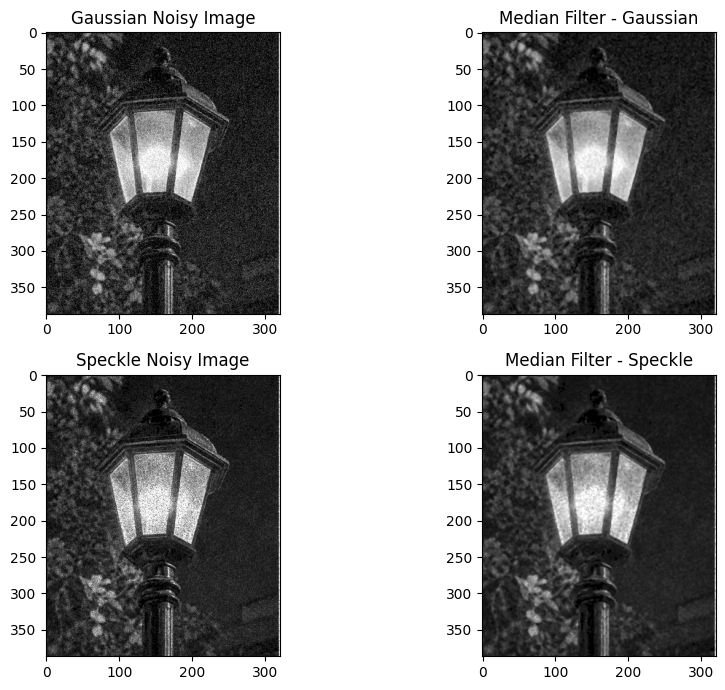

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread('/content/denoising.png', 0)

# Generate Gaussian noise
gaussian = np.random.normal(0, 20, img.shape)
gaussian_noisy = np.clip(img.astype(float) + gaussian, 0, 255).astype(np.uint8)

# Generate Speckle noise
speckle = np.random.normal(0, 0.2, img.shape)
speckle_noisy = np.clip(
    img.astype(float) + img.astype(float) * speckle, 0, 255
).astype(np.uint8)

# Apply Median Filter (3x3)
gaussian_filtered = cv2.medianBlur(gaussian_noisy, 3)
speckle_filtered = cv2.medianBlur(speckle_noisy, 3)

# Display results
plt.figure(figsize=(10, 7))

plt.subplot(2, 2, 1)
plt.imshow(gaussian_noisy, cmap='gray')
plt.title('Gaussian Noisy Image')

plt.subplot(2, 2, 2)
plt.imshow(gaussian_filtered, cmap='gray')
plt.title('Median Filter - Gaussian')

plt.subplot(2, 2, 3)
plt.imshow(speckle_noisy, cmap='gray')
plt.title('Speckle Noisy Image')

plt.subplot(2, 2, 4)
plt.imshow(speckle_filtered, cmap='gray')
plt.title('Median Filter - Speckle')

plt.tight_layout()
plt.show()

   (c) Gaussian filter  

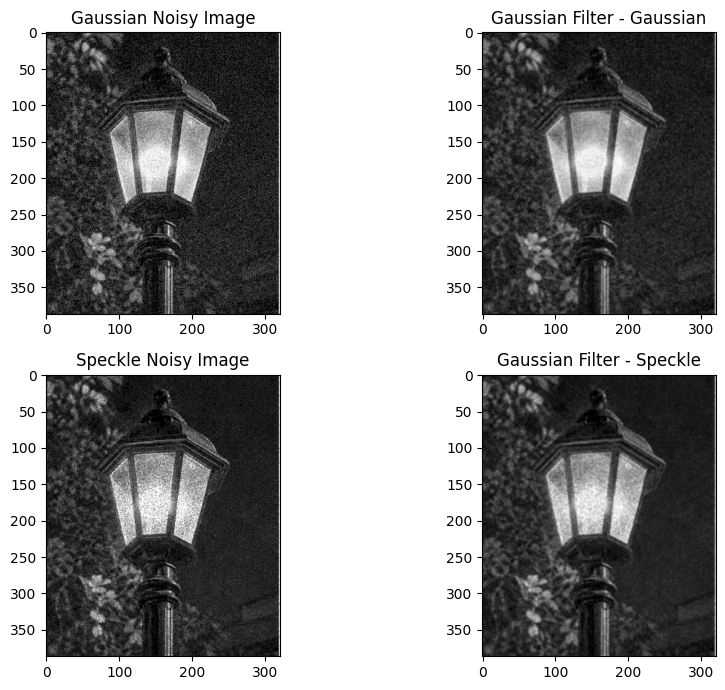

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread('/content/denoising.png', 0)

# Generate Gaussian noise
gaussian = np.random.normal(0, 20, img.shape)
gaussian_noisy = np.clip(img.astype(float) + gaussian, 0, 255).astype(np.uint8)

# Generate Speckle noise
speckle = np.random.normal(0, 0.2, img.shape)
speckle_noisy = np.clip(
    img.astype(float) + img.astype(float) * speckle, 0, 255
).astype(np.uint8)

# Apply Gaussian Filter (3x3)
gaussian_filtered = cv2.GaussianBlur(
    gaussian_noisy, (3, 3), 0
)

speckle_filtered = cv2.GaussianBlur(
    speckle_noisy, (3, 3), 0
)

# Display results
plt.figure(figsize=(10, 7))

plt.subplot(2, 2, 1)
plt.imshow(gaussian_noisy, cmap='gray')
plt.title('Gaussian Noisy Image')

plt.subplot(2, 2, 2)
plt.imshow(gaussian_filtered, cmap='gray')
plt.title('Gaussian Filter - Gaussian')

plt.subplot(2, 2, 3)
plt.imshow(speckle_noisy, cmap='gray')
plt.title('Speckle Noisy Image')

plt.subplot(2, 2, 4)
plt.imshow(speckle_filtered, cmap='gray')
plt.title('Gaussian Filter - Speckle')

plt.tight_layout()
plt.show()

   (d) Bilateral filter  

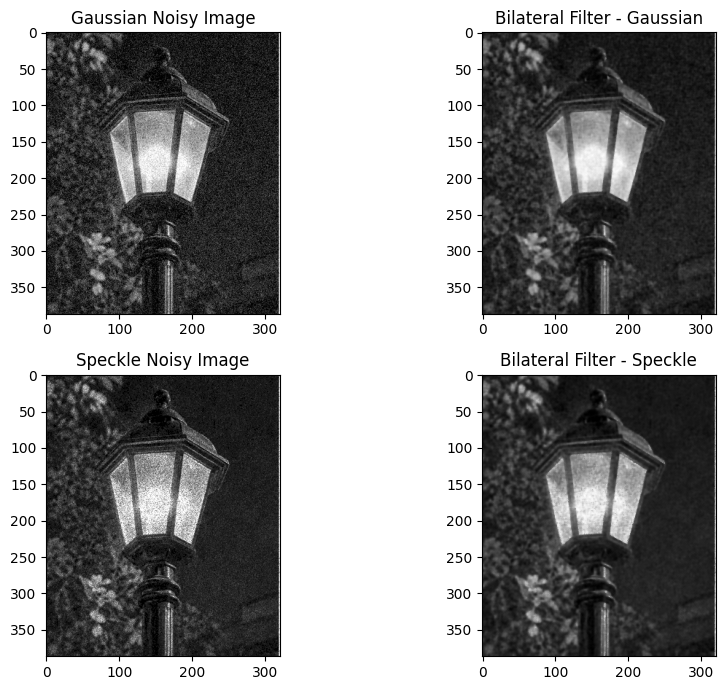

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread('/content/denoising.png', 0)

# Generate Gaussian noise
gaussian = np.random.normal(0, 20, img.shape)
gaussian_noisy = np.clip(img.astype(float) + gaussian, 0, 255).astype(np.uint8)

# Generate Speckle noise
speckle = np.random.normal(0, 0.2, img.shape)
speckle_noisy = np.clip(
    img.astype(float) + img.astype(float) * speckle, 0, 255
).astype(np.uint8)

# Apply Bilateral Filter (5x5)
gaussian_filtered = cv2.bilateralFilter(
    gaussian_noisy, 5, 75, 75
)

speckle_filtered = cv2.bilateralFilter(
    speckle_noisy, 5, 75, 75
)

# Display results
plt.figure(figsize=(10, 7))

plt.subplot(2, 2, 1)
plt.imshow(gaussian_noisy, cmap='gray')
plt.title('Gaussian Noisy Image')

plt.subplot(2, 2, 2)
plt.imshow(gaussian_filtered, cmap='gray')
plt.title('Bilateral Filter - Gaussian')

plt.subplot(2, 2, 3)
plt.imshow(speckle_noisy, cmap='gray')
plt.title('Speckle Noisy Image')

plt.subplot(2, 2, 4)
plt.imshow(speckle_filtered, cmap='gray')
plt.title('Bilateral Filter - Speckle')

plt.tight_layout()
plt.show()